In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load the standard Auto MPG dataset supplied by Seaborn.
cars = sns.load_dataset("mpg")

In [3]:
# Work on a copy so that the original data remain unchanged.
cars_clean = cars.copy()

In [4]:
# ----- Basic exploration -----
print("FIRST FIVE RECORDS")
print(cars_clean.head())

FIRST FIVE RECORDS
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  


In [5]:

# ----- Basic exploration -----
print("LAST FIVE RECORDS")
print(cars_clean.tail())

LAST FIVE RECORDS
      mpg  cylinders  displacement  horsepower  weight  acceleration  \
393  27.0          4         140.0        86.0    2790          15.6   
394  44.0          4          97.0        52.0    2130          24.6   
395  32.0          4         135.0        84.0    2295          11.6   
396  28.0          4         120.0        79.0    2625          18.6   
397  31.0          4         119.0        82.0    2720          19.4   

     model_year  origin             name  
393          82     usa  ford mustang gl  
394          82  europe        vw pickup  
395          82     usa    dodge rampage  
396          82     usa      ford ranger  
397          82     usa       chevy s-10  


In [6]:
# shape gives (number of rows, number of columns).
print("\nDataset shape =", cars_clean.shape)
print("Number of records =", cars_clean.shape[0])
print("Number of columns =", cars_clean.shape[1])


Dataset shape = (398, 9)
Number of records = 398
Number of columns = 9


In [7]:

print("\nColumn names:")
print(cars_clean.columns.tolist())


Column names:
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'name']


In [8]:
# dtypes helps us understand the kind of values stored in each column.
print("\nData types:")
print(cars_clean.dtypes)



Data types:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin           object
name             object
dtype: object


In [9]:
# info() shows non-null counts, data types and memory information.
print("\nDataset information:")
cars_clean.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [10]:
# Automatically identify numerical and categorical features.
numerical_features = cars_clean.select_dtypes(include=np.number).columns.tolist()
categorical_features = cars_clean.select_dtypes(include=["object", "category"]).columns.tolist()

print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)


Numerical features: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
Categorical features: ['origin', 'name']


In [11]:
# describe() reports count, mean, standard deviation, quartiles, min and max.
print("\nDescriptive statistics:")
print(cars_clean.describe())


Descriptive statistics:
              mpg   cylinders  displacement  horsepower       weight  \
count  398.000000  398.000000    398.000000  392.000000   398.000000   
mean    23.514573    5.454774    193.425879  104.469388  2970.424623   
std      7.815984    1.701004    104.269838   38.491160   846.841774   
min      9.000000    3.000000     68.000000   46.000000  1613.000000   
25%     17.500000    4.000000    104.250000   75.000000  2223.750000   
50%     23.000000    4.000000    148.500000   93.500000  2803.500000   
75%     29.000000    8.000000    262.000000  126.000000  3608.000000   
max     46.600000    8.000000    455.000000  230.000000  5140.000000   

       acceleration  model_year  
count    398.000000  398.000000  
mean      15.568090   76.010050  
std        2.757689    3.697627  
min        8.000000   70.000000  
25%       13.825000   73.000000  
50%       15.500000   76.000000  
75%       17.175000   79.000000  
max       24.800000   82.000000  


In [12]:
# ----- Missing values -----
missing_count = cars_clean.isnull().sum()
missing_percentage = cars_clean.isnull().mean() * 100

missing_table = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})
print("\nMissing-value summary:")
print(missing_table)



Missing-value summary:
              Missing_Count  Missing_Percentage
mpg                       0            0.000000
cylinders                 0            0.000000
displacement              0            0.000000
horsepower                6            1.507538
weight                    0            0.000000
acceleration              0            0.000000
model_year                0            0.000000
origin                    0            0.000000
name                      0            0.000000


In [13]:

# Horsepower contains missing values in the standard MPG dataset.
# Median is preferred here because it is less sensitive to extreme values.
horsepower_median = cars_clean["horsepower"].median()
cars_clean["horsepower"] = cars_clean["horsepower"].fillna(horsepower_median)

print("\nMissing horsepower after imputation =",
      cars_clean["horsepower"].isnull().sum())



Missing horsepower after imputation = 0


In [14]:
print(cars_clean.isnull().sum())

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [15]:

# ----- Duplicate records -----
print("\nDuplicates before removal =", cars_clean.duplicated().sum())
cars_clean = cars_clean.drop_duplicates()
print("Duplicates after removal =", cars_clean.duplicated().sum())



Duplicates before removal = 0
Duplicates after removal = 0


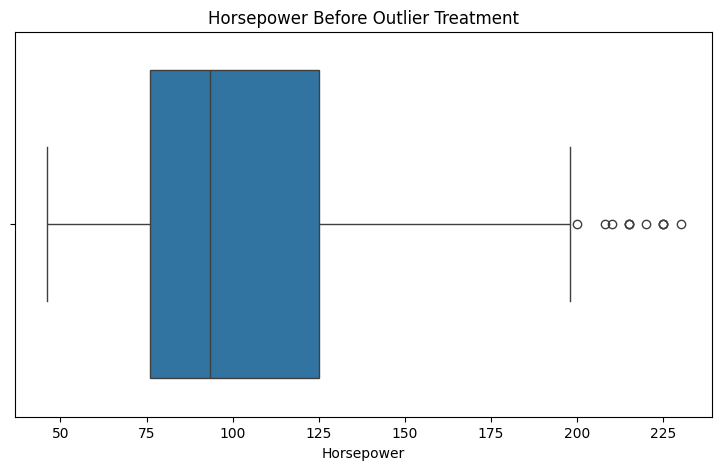

In [16]:
# ----- Outlier visualization before treatment -----
plt.figure(figsize=(9, 5))
sns.boxplot(x=cars_clean["horsepower"])
plt.title("Horsepower Before Outlier Treatment")
plt.xlabel("Horsepower")
plt.show()


In [17]:

# ----- IQR outlier detection -----
# Q1 = 25th percentile; Q3 = 75th percentile.
# IQR = Q3 - Q1.
# Conventional outlier limits are Q1 - 1.5*IQR and Q3 + 1.5*IQR.
Q1 = cars_clean["horsepower"].quantile(0.25)
Q3 = cars_clean["horsepower"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

horsepower_outliers = cars_clean[
    (cars_clean["horsepower"] < lower_limit) |
    (cars_clean["horsepower"] > upper_limit)
]

print("\nQ1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("Lower limit =", lower_limit)
print("Upper limit =", upper_limit)
print("Number of horsepower outliers =", len(horsepower_outliers))

print("\nOutlier records:")
print(horsepower_outliers[["name", "horsepower", "mpg", "weight"]])




Q1 = 76.0
Q3 = 125.0
IQR = 49.0
Lower limit = 2.5
Upper limit = 198.5
Number of horsepower outliers = 11

Outlier records:
                             name  horsepower   mpg  weight
6                chevrolet impala       220.0  14.0    4354
7               plymouth fury iii       215.0  14.0    4312
8                pontiac catalina       225.0  14.0    4425
13        buick estate wagon (sw)       225.0  14.0    3086
25                      ford f250       215.0  10.0    4615
26                      chevy c20       200.0  10.0    4376
27                     dodge d200       210.0  11.0    4382
67                mercury marquis       208.0  11.0    4633
94   chrysler new yorker brougham       215.0  13.0    4735
95       buick electra 225 custom       225.0  12.0    4951
116            pontiac grand prix       230.0  16.0    4278


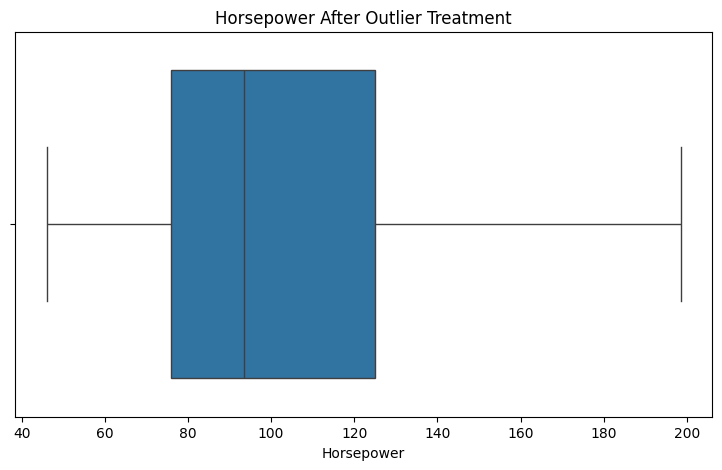

In [18]:

# ----- Outlier treatment by capping / winsorization -----
# Extreme values are capped rather than deleting the complete car record.
cars_clean["horsepower"] = cars_clean["horsepower"].clip(
    lower=lower_limit,
    upper=upper_limit
)

plt.figure(figsize=(9, 5))
sns.boxplot(x=cars_clean["horsepower"])
plt.title("Horsepower After Outlier Treatment")
plt.xlabel("Horsepower")
plt.show()



In [19]:

# ----- Final verification -----
print("\nRemaining missing values:")
print(cars_clean.isnull().sum())

print("\nRemaining duplicate records =", cars_clean.duplicated().sum())
print("Original shape =", cars.shape)
print("Cleaned shape =", cars_clean.shape)
print("\nCleaned data:")
print(cars_clean.head())



Remaining missing values:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Remaining duplicate records = 0
Original shape = (398, 9)
Cleaned shape = (398, 9)

Cleaned data:
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa        